# Verteilungen

**Notebook 1 von 5.** Eine explorative Analyse beschreibt Daten: das Histogramm einer Spalte,
ihren Mittelwert und ihre Streuung und wie stark zwei Spalten miteinander zusammenhängen. Dieses
Repository stellt zu jedem Muster, das eine solche Analyse findet, eine schärfere Frage:
**Könnte es einfach Zufall sein?**

Um sie zu beantworten, braucht es vor den eigentlichen Tests zwei Ideen, eine pro Notebook. Dies
ist die erste: eine **Verteilung**, die glatte Kurve hinter einem Histogramm, und die Tatsache,
dass **die Fläche unter dieser Kurve eine Wahrscheinlichkeit ist**. Jeder Hypothesentest in diesem
Repository endet damit, eine Fläche unter einer solchen Kurve abzulesen. Diese Fläche hat einen
Namen, den *p-Wert*, und deinen ersten berechnest du in `03_how_a_test_works.ipynb`.

Am Ende solltest du Folgendes können:

- entscheiden, ob eine Spalte diskret oder stetig ist, und eine Verteilung nennen, die sie
  modellieren könnte.
- eine Normalverteilung an eine Spalte anpassen und sie über das Histogramm zeichnen.
- die Wahrscheinlichkeit eines Wertes unterhalb, oberhalb oder zwischen Schwellenwerten bestimmen.
- den umgekehrten Weg gehen und den Bereich finden, der die mittleren 95 Prozent enthält.
- einen Wert in einen z-Wert umrechnen, also die Anzahl Standardabweichungen, die er vom
  Mittelwert entfernt liegt.
- erkennen, wann die Normalverteilungskurve das falsche Modell ist.
- die Kurve nennen, mit der ein Test sein Ergebnis vergleicht: t, Chi-Quadrat oder F.

Zuerst die Bibliotheken, die dieses Notebook braucht.

In [2]:
# Datenanalyse
import numpy as np
import pandas as pd

# Visualisierung
import matplotlib.pyplot as plt
import seaborn as sns

# Statistik: scipy.stats enthält jede Verteilung und jeden Test, der in diesem Repository verwendet wird
from scipy import stats

sns.set_style("whitegrid")

Dann die Daten: die **Palmer-Pinguine**, 344 Pinguine dreier Arten, die zwischen 2007 und 2009
auf drei Inseln in der Antarktis vermessen wurden.

Durch die nächsten drei Notebooks begleitest du eine Gruppe davon, die 68 **Zügelpinguine**
(*Chinstrap*). Hier beschreibst du, wie ihr Körpergewicht verteilt ist. In
`02_sampling_and_confidence_intervals.ipynb` schätzt du das durchschnittliche Körpergewicht der
Zügelpinguine und wie sicher du dir dabei sein kannst. In `03_how_a_test_works.ipynb` testest du
eine Behauptung darüber.

In [3]:
# 344 Pinguine, je eine Zeile
df_penguins = pd.read_csv("data/penguins.csv")
df_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
# nur die Zügelpinguine (Chinstrap) behalten
chinstrap = df_penguins[df_penguins["species"] == "Chinstrap"]
chinstrap["body_mass_g"].describe()

count      68.000000
mean     3733.088235
std       384.335081
min      2700.000000
25%      3487.500000
50%      3700.000000
75%      3950.000000
max      4800.000000
Name: body_mass_g, dtype: float64

Zwei Pinguine im vollständigen Datensatz haben überhaupt keine Messwerte, aber keiner davon ist ein
Zügelpinguin, sodass alle 68 Zeilen hier vollständig sind.

## 1. Vom Histogramm zur Kurve

Ein Histogramm aus 68 Pinguinen ist holprig. Wiegt man 68 andere Zügelpinguine, sähen die Balken
anders aus, obwohl es dieselbe Tierart ist. Gleich bleibt die **Form darunter**: wo die Gewichte
ungefähr ihr Zentrum haben, wie weit sie streuen und ob sie zu einer Seite hin auslaufen. Eine
**Verteilung** ist eine mathematische Beschreibung dieser Form.

Welche Verteilung man wählt, hängt zuerst davon ab, welche Art von Spalte man hat: Eine
**diskrete** Spalte zählt Dinge und nimmt ganze Zahlen an, eine **stetige** kann jeden Wert in
einem Bereich annehmen. Drei Verteilungen decken das meiste ab, was dir begegnen wird:

| Die Spalte ... | Typ | Verteilung |
| :--- | :--- | :--- |
| zählt Erfolge in einer festen Anzahl von Versuchen, z. B. geheilte Patienten von 20 | diskret | Binomial |
| zählt Ereignisse in einem festen Zeitraum, z. B. Support-Anrufe pro Stunde | diskret | Poisson |
| misst etwas, das jeden Wert in einem Bereich annehmen kann, z. B. eine Größe oder ein Gewicht | stetig | oft Normal |

Körpergewicht ist ein Messwert, also stetig. Die Messwerte einer einzelnen Tierart sind sehr oft
glockenförmig und symmetrisch um einen typischen Wert, was die **Normalverteilung** zur naheliegenden
Kandidatin macht.

Die Normalverteilung hat genau zwei Parameter: den **Mittelwert** $\mu$, wo die Glocke ihr
Zentrum hat, und die **Standardabweichung** $\sigma$, wie breit sie ist. Die wahren Werte für alle
Zügelpinguine kennen wir nicht, also verwenden wir Mittelwert und Standardabweichung unserer 68.

In [5]:
mass = chinstrap["body_mass_g"]

# die zwei Zahlen, die eine Normalverteilungskurve festlegen
mean_mass = mass.mean()
std_mass = mass.std()

print(f"Mittelwert         : {mean_mass:.1f} g")
print(f"Standardabweichung : {std_mass:.1f} g")

Mittelwert         : 3733.1 g
Standardabweichung : 384.3 g


Um eine Kurve über ein Histogramm zu legen, müssen beide auf derselben Skala gezeichnet werden.
`stat="density"` skaliert die Balken so um, dass ihre Gesamtfläche 1 beträgt; das ist die Skala,
auf der eine Verteilungskurve lebt. `stats.norm.pdf` liefert dann die Höhe der Normalverteilungskurve
an jedem Punkt, nach dem wir fragen.

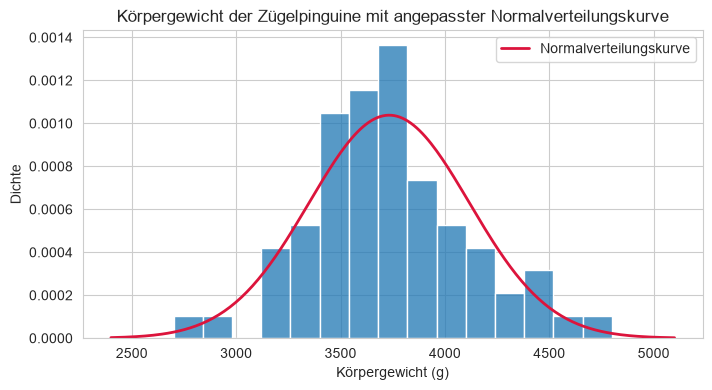

In [6]:
# 200 gleichmäßig verteilte Gewichte, etwas über den leichtesten und schwersten Pinguin hinaus
x = np.linspace(mass.min() - 300, mass.max() + 300, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# Dichteskala: Die Gesamtfläche der Balken ist 1
sns.histplot(mass, stat="density", bins=15, ax=ax)

# die Normalverteilungskurve mit unserem Mittelwert und unserer Standardabweichung
ax.plot(x, stats.norm.pdf(x, loc=mean_mass, scale=std_mass), color="crimson", linewidth=2,
        label="Normalverteilungskurve")

ax.set_title("Körpergewicht der Zügelpinguine mit angepasster Normalverteilungskurve")
ax.set_xlabel("Körpergewicht (g)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

Die Kurve folgt den Balken recht gut: ein Gipfel nahe dem Mittelwert und ein Abfall, der auf beiden
Seiten etwa gleich ist. Eine perfekte Übereinstimmung ist es nicht, und mit 68 Pinguinen wird es
das auch nie sein, aber es ist eine faire Zusammenfassung der Form.

> **Hinweis.** Die Höhe der Kurve ist eine *Dichte*, keine Wahrscheinlichkeit. Die
> Wahrscheinlichkeit, dass ein Pinguin genau 3.733,0000 g wiegt, ist null. Wahrscheinlichkeiten
> gehören zu **Bereichen** von Werten, und darum geht es im nächsten Abschnitt.

> **Übung:**
>
> Mach dasselbe für die **Flossenlänge** der Zügelpinguine, `flipper_length_mm`. Berechne
> Mittelwert und Standardabweichung, zeichne dann das Histogramm auf der Dichteskala mit der
> angepassten Normalverteilungskurve darüber. Ist die Normalverteilung ein faires Modell dafür?

Mittelwert         : 195.8 mm
Standardabweichung : 7.1 mm


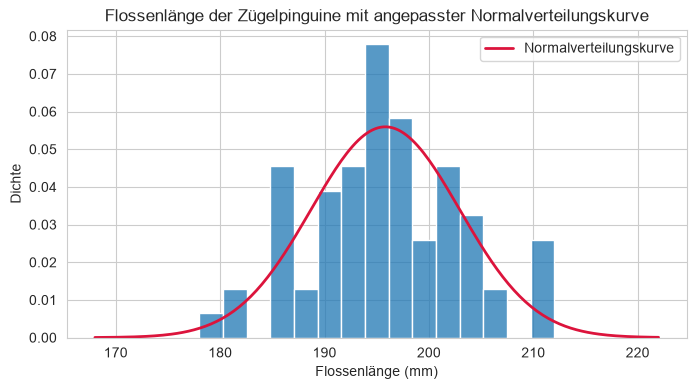

In [8]:
flipper = chinstrap["flipper_length_mm"]

# die zwei Zahlen, die die Normalverteilungskurve festlegen
mean_flipper = flipper.mean()
std_flipper = flipper.std()

print(f"Mittelwert         : {mean_flipper:.1f} mm")
print(f"Standardabweichung : {std_flipper:.1f} mm")

# etwas über die kürzeste und längste Flosse hinaus
x = np.linspace(flipper.min() - 10, flipper.max() + 10, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# Dichteskala: Die Gesamtfläche der Balken ist 1
sns.histplot(flipper, stat="density", bins=15, ax=ax)

# die Normalverteilungskurve mit Mittelwert und Standardabweichung der Flossenlänge
ax.plot(x, stats.norm.pdf(x, loc=mean_flipper, scale=std_flipper), color="crimson", linewidth=2,
        label="Normalverteilungskurve")

ax.set_title("Flossenlänge der Zügelpinguine mit angepasster Normalverteilungskurve")
ax.set_xlabel("Flossenlänge (mm)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

## 2. Die Fläche unter der Kurve ist eine Wahrscheinlichkeit

Sobald die Kurve angepasst ist, hat eine Frage wie *„Wie wahrscheinlich wiegt ein Zügelpinguin
weniger als 3.500 g?"* eine präzise Antwort: Es ist die **Fläche unter der Kurve links von 3.500**.
Die gesamte Fläche ist 1, also ist jeder Teil davon ein Anteil zwischen 0 und 1.

`stats.norm.cdf`, die **kumulative Verteilungsfunktion**, liefert genau diese Fläche: alles links
von dem Wert, den du ihr übergibst.

In [9]:
threshold = 3500

# Fläche links vom Schwellenwert unter der angepassten Kurve
p_below_model = stats.norm.cdf(threshold, loc=mean_mass, scale=std_mass)

# dieselbe Frage direkt an die 68 Pinguine gestellt
p_below_data = (mass < threshold).mean()

print(f"Modell: {p_below_model:.1%} der Zügelpinguine wiegen weniger als {threshold} g")
print(f"Daten : {p_below_data:.1%} ({(mass < threshold).sum()} von {len(mass)} Pinguinen)")

Modell: 27.2% der Zügelpinguine wiegen weniger als 3500 g
Daten : 25.0% (17 von 68 Pinguinen)


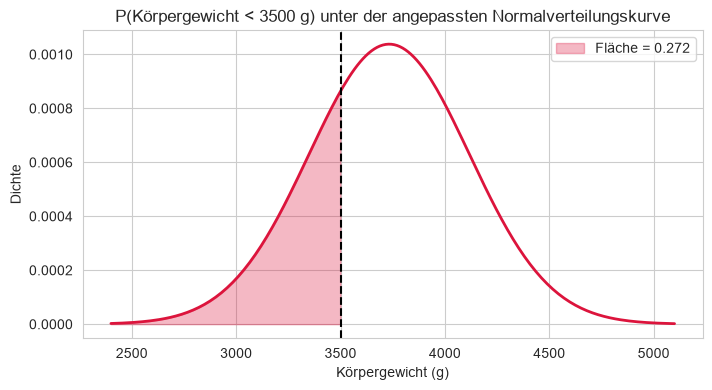

In [10]:
x = np.linspace(mass.min() - 300, mass.max() + 300, 200)
y = stats.norm.pdf(x, loc=mean_mass, scale=std_mass)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, color="crimson", linewidth=2)

# die Fläche schattieren, die cdf gerade gemessen hat
ax.fill_between(x, y, where=(x <= threshold), color="crimson", alpha=0.3,
                label=f"Fläche = {p_below_model:.3f}")

ax.axvline(threshold, color="black", linestyle="--")
ax.set_title(f"P(Körpergewicht < {threshold} g) unter der angepassten Normalverteilungskurve")
ax.set_xlabel("Körpergewicht (g)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

Das Modell sagt 27 Prozent, und tatsächlich wiegen 17 der 68 Pinguine, also 25 Prozent, weniger
als 3.500 g. Die beiden stimmen eng überein, wie es ein gut passendes Modell tun sollte. Die Antwort
des Modells ist außerdem *glatter*: Sie springt nicht, wenn ein einzelner Pinguin die Linie
überschreitet.

Zwei weitere Flächen ergeben sich aus derselben Funktion:

- **Oberhalb** eines Wertes ist alles, was nicht darunter liegt: `1 - stats.norm.cdf(value, ...)`.
- **Zwischen** zwei Werten ist die Fläche links vom oberen minus die Fläche links vom unteren:
  `stats.norm.cdf(upper, ...) - stats.norm.cdf(lower, ...)`.

> **Übung:**
>
> Mit der Normalverteilungskurve, die du an die Flossenlänge der Zügelpinguine angepasst hast:
>
> 1. Welcher Anteil der Zügelpinguine hat laut Modell Flossen **länger als 200 mm**?
>    Vergleiche ihn mit dem Anteil in den Daten.
> 2. Welchen Anteil legt das Modell **zwischen 190 und 200 mm**?

<details><summary>
Klicke hier für einen Tipp ...
</summary>

`mean_flipper` und `std_flipper` hast du schon aus der letzten Übung. Übergib sie als `loc` und
`scale`. Für den Anteil in den Daten funktioniert `(flipper > 200).mean()` genauso wie im
Körpergewicht-Beispiel oben.
</details>

In [11]:
# Fläche rechts von 200 mm: alles, was nicht links davon liegt
p_above_model = 1 - stats.norm.cdf(200, loc=mean_flipper, scale=std_flipper)

# dieselbe Frage direkt an die 68 Pinguine gestellt
p_above_data = (flipper > 200).mean()

print(f"Modell: {p_above_model:.1%} der Zügelpinguine haben Flossen länger als 200 mm")
print(f"Daten : {p_above_data:.1%} ({(flipper > 200).sum()} von {len(flipper)} Pinguinen)")

Modell: 27.9% der Zügelpinguine haben Flossen länger als 200 mm
Daten : 26.5% (18 von 68 Pinguinen)


In [12]:
# Fläche links von 200 mm minus Fläche links von 190 mm
p_between_model = (stats.norm.cdf(200, loc=mean_flipper, scale=std_flipper)
                   - stats.norm.cdf(190, loc=mean_flipper, scale=std_flipper))

# zum Vergleich der Anteil in den Daten
p_between_data = flipper.between(190, 200).mean()

print(f"Modell: {p_between_model:.1%} der Zügelpinguine haben Flossen zwischen 190 und 200 mm")
print(f"Daten : {p_between_data:.1%} ({flipper.between(190, 200).sum()} von {len(flipper)} Pinguinen)")

Modell: 51.4% der Zügelpinguine haben Flossen zwischen 190 und 200 mm
Daten : 55.9% (38 von 68 Pinguinen)


## 3. Rückwärts: von einer Wahrscheinlichkeit zu einem Wert

`cdf` nimmt einen Wert und liefert eine Fläche. Ihre Umkehrung, `stats.norm.ppf` (die
*Quantilfunktion*, auf Englisch *percent point function*), nimmt eine Fläche und liefert den Wert,
der sie abschneidet.

Die Frage, die sie am häufigsten beantwortet, lautet: **Welcher Bereich enthält die mittleren 95
Prozent?** Schneide an jedem Rand 2,5 Prozent ab und lies die beiden Werte ab, an denen die
Schnitte liegen.

In [13]:
# die Werte, die an jedem Rand 2,5 % der Fläche übrig lassen
lower, upper = stats.norm.ppf([0.025, 0.975], loc=mean_mass, scale=std_mass)
print(f"mittlere 95 % des Körpergewichts der Zügelpinguine: {lower:.0f} g bis {upper:.0f} g")

# wie viele unserer Pinguine liegen tatsächlich in diesem Bereich?
inside = mass.between(lower, upper)
print(f"Pinguine innerhalb: {inside.sum()} von {len(mass)} ({inside.mean():.1%})")

mittlere 95 % des Körpergewichts der Zügelpinguine: 2980 g bis 4486 g
Pinguine innerhalb: 63 von 68 (92.6%)


Das Modell legt die mittleren 95 Prozent der Zügelpinguine zwischen etwa 2.980 g und 4.486 g, und
63 unserer 68 Pinguine liegen darin.

### z-Werte und die Zahl 1,96

Ein Abstand in Gramm bedeutet nur dann etwas, wenn man weiß, wie stark die Gewichte streuen. Der
**z-Wert** entfernt die Einheiten, indem er stattdessen in Standardabweichungen zählt:

$$
z = \frac{x - \mu}{\sigma}
$$

Ein z-Wert von 0 ist genau durchschnittlich; +2 liegt zwei Standardabweichungen darüber. Wandelt
man jeden Wert so um, wird aus jeder Normalverteilungskurve dieselbe, die **Standardnormalverteilung**
mit Mittelwert 0 und Standardabweichung 1. Das ist `stats.norm` ganz ohne `loc` oder `scale`.

Frag die Standardnormalverteilung, wo ihre mittleren 95 Prozent enden:

In [14]:
# kein loc oder scale: die Standardnormalverteilung, Mittelwert 0 und Standardabweichung 1
z_crit = stats.norm.ppf(0.975)
print(f"die mittleren 95 % jeder Normalverteilung liegen innerhalb von {z_crit:.2f} "
      "Standardabweichungen um ihren Mittelwert")

die mittleren 95 % jeder Normalverteilung liegen innerhalb von 1.96 Standardabweichungen um ihren Mittelwert


**Merk dir 1,96.** Das gilt für jede Normalverteilung, egal was sie misst, und die Zahl taucht in
diesem Repository zweimal wieder auf: In `02_sampling_and_confidence_intervals.ipynb` baut sie ein
Konfidenzintervall, und in `03_how_a_test_works.ipynb` ist sie die Linie, die ein Testergebnis
überschreiten muss, um als überraschend zu gelten.

Nimm jetzt einen schweren Zügelpinguin mit 4.500 g und frag, wie ungewöhnlich er ist.

In [15]:
heavy = 4500

# wie viele Standardabweichungen über dem Mittelwert?
z_heavy = (heavy - mean_mass) / std_mass
print(f"z-Wert eines Zügelpinguins mit {heavy} g: {z_heavy:.2f}")

# die Fläche dahinter, auf zwei Arten gefragt: auf der Gramm-Skala und auf der z-Skala
print(f"schwerer als dieser, Gramm-Skala: {1 - stats.norm.cdf(heavy, loc=mean_mass, scale=std_mass):.2%}")
print(f"schwerer als dieser, z-Skala    : {1 - stats.norm.cdf(z_heavy):.2%}")

z-Wert eines Zügelpinguins mit 4500 g: 2.00
schwerer als dieser, Gramm-Skala: 2.30%
schwerer als dieser, z-Skala    : 2.30%


Ein Zügelpinguin mit 4.500 g liegt 2,0 Standardabweichungen über dem Mittelwert, und laut Modell
sind nur etwa 2,3 Prozent der Zügelpinguine schwerer. Beide Skalen liefern dieselbe Fläche, weil der
z-Wert nur die Achse umbeschriftet.

Genau so wird ein Hypothesentest in Notebook 03 ein Ergebnis beurteilen: Er übersetzt es in *wie
viele Standardeinheiten entfernt von dem, was wir erwartet haben* und misst dann, *wie viel Fläche
dahinter liegt*. Eine kleine Fläche bedeutet ein überraschendes Ergebnis.

> **Übung:**
>
> Zurück zur Flossenlänge der Zügelpinguine.
>
> 1. Welcher Bereich enthält laut Modell die mittleren 95 Prozent der Flossenlängen?
> 2. Wie lautet der z-Wert eines Zügelpinguins mit einer 210 mm langen Flosse, und welcher Anteil
>    der Zügelpinguine hat laut Modell eine mindestens so lange Flosse?

In [16]:
# die Werte, die an jedem Rand 2,5 % der Fläche übrig lassen
lower_flipper, upper_flipper = stats.norm.ppf([0.025, 0.975], loc=mean_flipper, scale=std_flipper)
print(f"mittlere 95 % der Flossenlänge: {lower_flipper:.1f} mm bis {upper_flipper:.1f} mm")

# wie viele unserer Pinguine liegen tatsächlich in diesem Bereich?
inside_flipper = flipper.between(lower_flipper, upper_flipper)
print(f"Pinguine innerhalb: {inside_flipper.sum()} von {len(flipper)} ({inside_flipper.mean():.1%})")

mittlere 95 % der Flossenlänge: 181.8 mm bis 209.8 mm
Pinguine innerhalb: 61 von 68 (89.7%)


In [17]:
long_flipper = 210

# wie viele Standardabweichungen über dem Mittelwert?
z_long = (long_flipper - mean_flipper) / std_flipper
print(f"z-Wert einer Flosse von {long_flipper} mm: {z_long:.2f}")

# die Fläche ab diesem Wert, auf der z-Skala
print(f"Anteil mit mindestens {long_flipper} mm laut Modell: {1 - stats.norm.cdf(z_long):.2%}")

# zum Vergleich in den Daten
print(f"Anteil in den Daten: {(flipper >= long_flipper).mean():.2%} "
      f"({(flipper >= long_flipper).sum()} von {len(flipper)} Pinguinen)")

z-Wert einer Flosse von 210 mm: 1.99
Anteil mit mindestens 210 mm laut Modell: 2.34%
Anteil in den Daten: 5.88% (4 von 68 Pinguinen)


## 4. Wenn die Normalverteilung das falsche Modell ist

Jede bisherige Berechnung hat der angepassten Kurve vertraut. Dieses Vertrauen wurde verdient,
indem wir zuerst das Histogramm angesehen und **jeweils nur eine Art** modelliert haben. Die
nächste Übung zeigt, was ohne diese Sorgfalt passiert.

> **Übung:**
>
> Nimm das Körpergewicht **aller** Pinguine, alle Arten zusammen.
>
> 1. Entferne die beiden fehlenden Werte, passe eine Normalverteilungskurve an und zeichne sie wie
>    in Abschnitt 1 über das Histogramm.
> 2. Frag das Modell, welcher Anteil der Pinguine weniger als 3.000 g wiegt, und vergleiche ihn mit
>    den Daten. Mach dann dasselbe für weniger als 2.700 g.
> 3. In ein oder zwei Sätzen: Warum liegt das Modell hier falsch?

<details><summary>
Klicke hier für einen Tipp ...
</summary>

`df_penguins["body_mass_g"].dropna()` liefert die 342 Gewichte. Für Frage 3 färbe das Histogramm
nach Art ein: `sns.histplot(data=df_penguins, x="body_mass_g", hue="species",
multiple="stack")`.
</details>

Mittelwert         : 4201.8 g
Standardabweichung : 802.0 g


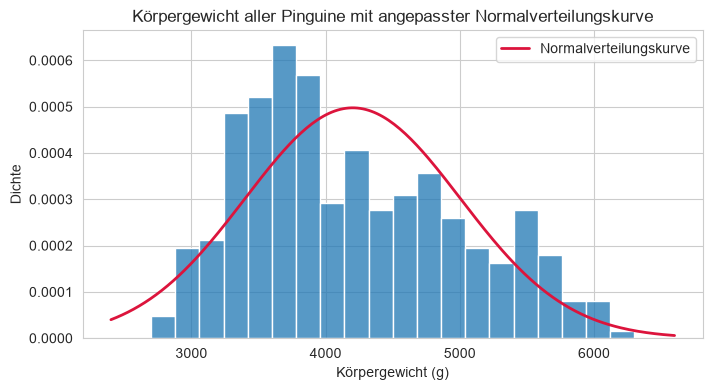

In [22]:
# dein Code: Normalverteilungskurve für das Körpergewicht aller Pinguine anpassen und zeichnen
# alle Pinguine, beide fehlenden Werte entfernt (342 Gewichte)
mass_all = df_penguins["body_mass_g"].dropna()

mean_all = mass_all.mean()
std_all = mass_all.std()

print(f"Mittelwert         : {mean_all:.1f} g")
print(f"Standardabweichung : {std_all:.1f} g")

x = np.linspace(mass_all.min() - 300, mass_all.max() + 300, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# Dichteskala: Die Gesamtfläche der Balken ist 1
sns.histplot(mass_all, stat="density", bins=20, ax=ax)

# die Normalverteilungskurve mit Mittelwert und Standardabweichung aller Pinguine
ax.plot(x, stats.norm.pdf(x, loc=mean_all, scale=std_all), color="crimson", linewidth=2,
        label="Normalverteilungskurve")

ax.set_title("Körpergewicht aller Pinguine mit angepasster Normalverteilungskurve")
ax.set_xlabel("Körpergewicht (g)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()


In [23]:
# dein Code: Modell und Daten unter 3.000 g und unter 2.700 g vergleichen
for limit in [3000, 2700]:
    p_model = stats.norm.cdf(limit, loc=mean_all, scale=std_all)
    p_data = (mass_all < limit).mean()
    print(f"unter {limit} g -> Modell: {p_model:.1%}, "
          f"Daten: {p_data:.1%} ({(mass_all < limit).sum()} von {len(mass_all)} Pinguinen)")


unter 3000 g -> Modell: 6.7%, Daten: 2.6% (9 von 342 Pinguinen)
unter 2700 g -> Modell: 3.1%, Daten: 0.0% (0 von 342 Pinguinen)


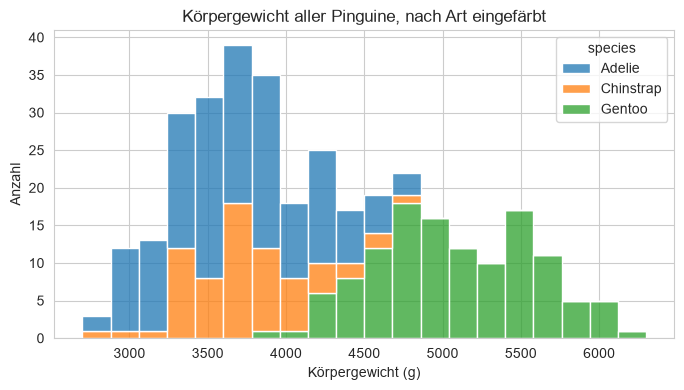

In [24]:
# dein Code (optional): das Histogramm nach Art einfärben, um zu sehen, warum
fig, ax = plt.subplots(figsize=(8, 4))

# gestapelt nach Art: zeigt die drei Gruppen hinter dem zweiten Buckel
sns.histplot(data=df_penguins, x="body_mass_g", hue="species", multiple="stack", bins=20, ax=ax)

ax.set_title("Körpergewicht aller Pinguine, nach Art eingefärbt")
ax.set_xlabel("Körpergewicht (g)")
ax.set_ylabel("Anzahl")
plt.show()


<details><summary>
Klicke hier, um deine Antwort auf Frage 3 zu vergleichen ...
</summary>

Das Modell legt etwa 6,7 Prozent der Pinguine unter 3.000 g, wo die Daten 2,6 Prozent haben, und
etwa 3 Prozent unter 2.700 g, wo die Daten keinen einzigen haben: Der leichteste Pinguin wiegt genau
2.700 g.

Die Daten sind keine einzelne Glocke, sondern eine **Mischung**. Adeliepinguine und Zügelpinguine
wiegen im Schnitt etwa 3.700 g, Eselspinguine (*Gentoo*) etwa 5.100 g. Zusammengelegt ergeben sie
eine schiefe Form mit einem zweiten Buckel rechts. Eine einzelne Normalverteilungskurve kann sich
nicht so biegen, dass sie dazu passt, also wird sie breit gezogen, um beide Buckel abzudecken, und
ihr linker Rand reicht in Gewichte hinein, die kein Pinguin hat.
</details>

Die Lehre gilt für jeden folgenden Test: **Sieh dir das Histogramm an, bevor du der Kurve
vertraust.** Die Tests in den Notebooks 03 bis 05 treffen Annahmen über die Form der Daten, und
deren Überprüfung beginnt mit einem Plot.

## 5. Kurven für Testergebnisse

Jede Kurve bisher hat **Daten** beschrieben: hier Pinguingewichte und die Zählungen in der Tabelle
aus Abschnitt 1. Hypothesentests brauchen eine zweite Art von Kurve. Ein Test verdichtet einen
ganzen Datensatz auf **eine Zahl**, seine *Teststatistik*, und fragt dann, wo diese Zahl auf einer
Kurve liegt, die beschreibt, wie sie allein durch Zufall schwanken würde.

Diese Kurven passt du nie an eine Spalte an, und scipy verwendet sie für dich. Aber drei von ihnen
erledigen die ganze Arbeit in diesem Repository, daher lohnt es sich, sie einmal zu sehen, bevor
es darauf ankommt:

| Kurve | Was die Teststatistik misst | Wo sie dir begegnet |
| :--- | :--- | :--- |
| **t** | wie weit ein Mittelwert von einem behaupteten Wert entfernt liegt, in Standardfehlern | Notebooks 02 und 03, dann der t-Test und der Korrelationstest in 04 |
| **Chi-Quadrat** | wie weit die Häufigkeiten in einer Tabelle von den erwarteten Häufigkeiten abweichen, wenn zwei Spalten unabhängig wären | der Chi-Quadrat-Test in 04 |
| **F** | wie weit mehrere Gruppenmittelwerte auseinanderliegen, verglichen mit der Streuung innerhalb jeder Gruppe | ANOVA in 04 |

Jede hat einen Formparameter namens **Freiheitsgrade**, der davon abhängt, wie viele Daten in die
Statistik eingeflossen sind. Der Plot zeigt jede Kurve mit zwei Einstellungen; die durchgezogene
Linie in jedem Feld ist die Einstellung, die die Rechenbeispiele in den Notebooks 03 und 04
verwenden.

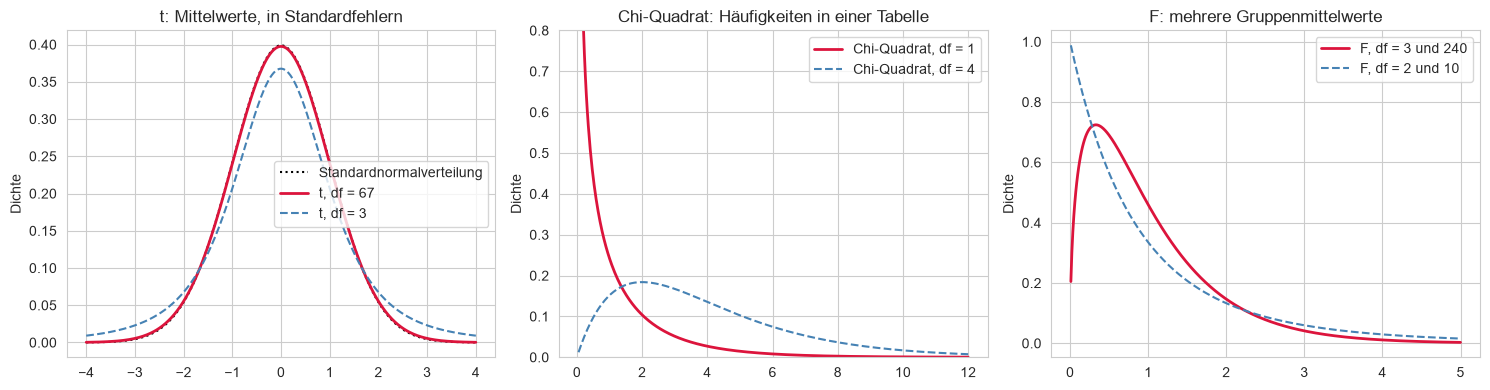

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# t: glockenförmig um 0, wie die Standardnormalverteilung (gepunktet), aber mit schwereren Rändern
x = np.linspace(-4, 4, 400)
axes[0].plot(x, stats.norm.pdf(x), color="black", linestyle=":", label="Standardnormalverteilung")
axes[0].plot(x, stats.t.pdf(x, df=67), color="crimson", linewidth=2, label="t, df = 67")
axes[0].plot(x, stats.t.pdf(x, df=3), color="steelblue", linestyle="--", label="t, df = 3")
axes[0].set_title("t: Mittelwerte, in Standardfehlern")

# Chi-Quadrat: aus quadrierten Abständen gebaut, beginnt also bei 0 und wird nie negativ
x = np.linspace(0.05, 12, 400)
axes[1].plot(x, stats.chi2.pdf(x, df=1), color="crimson", linewidth=2, label="Chi-Quadrat, df = 1")
axes[1].plot(x, stats.chi2.pdf(x, df=4), color="steelblue", linestyle="--",
             label="Chi-Quadrat, df = 4")
axes[1].set_ylim(0, 0.8)
axes[1].set_title("Chi-Quadrat: Häufigkeiten in einer Tabelle")

# F: ein Verhältnis zweier Streuungen, beginnt also auch bei 0; es hat zwei Freiheitsgrade
x = np.linspace(0.01, 5, 400)
axes[2].plot(x, stats.f.pdf(x, dfn=3, dfd=240), color="crimson", linewidth=2,
             label="F, df = 3 und 240")
axes[2].plot(x, stats.f.pdf(x, dfn=2, dfd=10), color="steelblue", linestyle="--",
             label="F, df = 2 und 10")
axes[2].set_title("F: mehrere Gruppenmittelwerte")

for ax in axes:
    ax.set_ylabel("Dichte")
    ax.legend()

plt.tight_layout()
plt.show()

Drei Dinge, die du aus dem Bild mitnehmen solltest:

- **t** ist ein enger Verwandter der Standardnormalverteilung: um 0 zentriert, symmetrisch, mit
  schwereren Rändern, wenn es wenige Freiheitsgrade gibt. Bei 67, der Einstellung, die Notebook 03
  für die 68 Zügelpinguine verwendet, ist sie von der Normalverteilungskurve kaum zu unterscheiden.
- **Chi-Quadrat** und **F** beginnen bei 0 und laufen nach rechts aus. Ihre Statistiken werden aus
  quadrierten Abständen und Verhältnissen von Streuungen gebildet, können also nie negativ sein,
  und nur ein **großer** Wert ist überraschend.
- **Flächen funktionieren genau wie in Abschnitt 2.** `stats.t`, `stats.chi2` und `stats.f` haben
  alle `cdf` und `ppf`, genau wie `stats.norm`. Jeder p-Wert in diesem Repository ist eine Fläche
  unter einer dieser drei Kurven.

## Zusammenfassung

In diesem Notebook hast du:

- eine Spalte anhand ihres Typs und ihrer Form einer Verteilung zugeordnet.
- eine Normalverteilungskurve mit zwei Zahlen, Mittelwert und Standardabweichung, an das
  Körpergewicht der Zügelpinguine angepasst.
- Wahrscheinlichkeiten als Flächen unter dieser Kurve abgelesen, mit `stats.norm.cdf`.
- mit `stats.norm.ppf` den Weg von einer Fläche zurück zu einem Wert gefunden und die 1,96
  kennengelernt.
- mit dem z-Wert gemessen, wie ungewöhnlich ein Wert ist.
- gesehen, wie eine Normalverteilungskurve an Daten scheitert, die eigentlich eine Mischung aus
  drei Gruppen sind.
- die drei Kurven kennengelernt, mit denen Tests ihre Ergebnisse vergleichen: t, Chi-Quadrat und F.

Alles hier hat **einzelne Pinguine** beschrieben. Das nächste Notebook fragt nach dem
**durchschnittlichen** Pinguin: Hättest du 68 andere Zügelpinguine gewogen, wie stark hätte sich
der Mittelwert verändert? Die Antwort ist eine weitere Normalverteilungskurve, und die 1,96 kommt
direkt zurück.

## Quellen & weiterführende Literatur

- [**scipy.stats.norm**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html):
  Die Normalverteilung mit `pdf`, `cdf`, `ppf` und ihren übrigen Methoden.
  [`scipy.stats.t`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html),
  [`chi2`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html) und
  [`f`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f.html)
  haben dieselben Methoden.
- [**Seeing Theory: Probability Distributions**](https://seeing-theory.brown.edu/probability-distributions/index.html):
  Interaktive, visuelle Erklärungen der Verteilungen aus der Tabelle in Abschnitt 1 (englisch).
- [**seaborn.histplot**](https://seaborn.pydata.org/generated/seaborn.histplot.html):
  Das durchgehend verwendete Histogramm, einschließlich der Option `stat="density"`.
- [**palmerpenguins**](https://allisonhorst.github.io/palmerpenguins/): Die Herkunft des Datensatzes,
  erhoben von Dr. Kristen Gorman an der Palmer Station in der Antarktis.